# Introduction to Bayesian Modelling

## Bayes' theorem | Priors and posteriors | Conjugate priors | Markov chain Monte Carlo |

**MPhil in Past and Future Climates, University of Cambridge – Methods 03, Friday 30 October 2026**

---

This practical builds a **Bayesian statistical model** from scratch, using nothing but NumPy and SciPy. We start with the simplest possible problem — is a coin fair? — to see how Bayes' theorem turns a **prior** belief and some data into a **posterior** belief, and how a **conjugate prior** gives the answer in one line of algebra. We then move to a real dataset: daily melt measured on a glacier in Spitsbergen. A classical regression fits these data well but predicts *negative melting*, which is physically impossible. We fix it the Bayesian way, by writing the physics into the prior, and because that model has no one-line answer we write our own **Markov chain Monte Carlo (MCMC)** sampler to explore the posterior.

### Aims and learning outcomes

By the end of this practical you should be able to:

* explain, in words, what a prior, a likelihood and a posterior are, and how Bayes' theorem connects them;
* update a prior with data and read a **credible interval** from the posterior;
* say what a **conjugate prior** gives you, and recognise when a model has no conjugate shortcut;
* run a **Metropolis sampler** and judge whether it worked (acceptance rate, trace plots, burn-in);
* build a physical constraint into a model through its prior, and say what that changes in the result.

---

Main libraries: [numpy](https://numpy.org/) (numbers and arrays), [scipy.stats](https://docs.scipy.org/doc/scipy/reference/stats.html) (statistical distributions), [pandas](https://pandas.pydata.org/) (tables), [matplotlib](https://matplotlib.org/) (plots). Nothing else: no Bayesian library, so you see every moving part.

**How to use this notebook:** run the cells from top to bottom (`Shift + Enter`). Each code cell has a short note above it saying what it does and why. You do not need to write code from scratch: the *Your turn* boxes ask you to change one or two numbers.

Instructor: Francesco Muschitiello (fm476), October 2026.

---

### Setup: import the libraries

We load every library we need once, here at the top, and create a seeded random generator so that everyone gets the same numbers.

In [1]:
import numpy as np              # numbers and arrays
import pandas as pd             # tables
import matplotlib.pyplot as plt # plots
import scipy.stats as stats     # statistical distributions

rng = np.random.default_rng(42) # a seeded random generator, for reproducibility

# Readable, consistent figures
plt.rcParams.update({"font.size": 12, "axes.titlesize": 13, "figure.dpi": 100})

### Check that the data are found

A quick check that the notebook can see the data. For a full check of your installation run `python check_setup.py` (see README).

In [2]:
from pathlib import Path

# data folder, relative to this notebook (repository layout, or a flat layout with data next to practicals)
DATA = next((d for d in (Path("../../data/03_methods"), Path("../data")) if (d / "glacier_melt").is_dir()), Path("../../data/03_methods"))
MELT_FILE = DATA / "glacier_melt" / "Glac_Melt.csv"

assert MELT_FILE.exists(), "Data not found. Open this notebook from practicals/03_methods (see README)."
print("Data found:", MELT_FILE)

Data found: ../../data/03_methods/glacier_melt/Glac_Melt.csv


---
# Part 1 – Bayes' theorem with a coin

## 1a. What is Bayesian statistics?

**Bayesian statistics is a way of updating our beliefs based on new evidence.** You start with an initial belief (the *prior*), collect data, and revise that belief into an updated one (the *posterior*). In a sense, this mirrors the process of learning itself — and it forms a foundational framework for much of machine learning.

The Frequentist vs Bayesian debate has a long history, but from a practical point of view: **Bayesian methods are better suited to "dirty" data — small and noisy** — which is the norm in Earth science.

| Feature | Frequentist | Bayesian |
|---|---|---|
| **Probability** | Objective (frequency of data) | Degree of belief (data + prior) |
| **Parameters** | Fixed unknown constants | Random variables with distributions |
| **Inference** | Likelihood maximisation | Bayes' theorem (update prior with data) |
| **Estimates** | Point estimates + confidence intervals | Full posteriors + credible intervals |
| **Prior knowledge** | No | Yes |

*Trade-offs*: Bayesian models can be computationally expensive, and results can be sensitive to the choice of priors — so prior choices must always be justified.

The community has noticed — the use of Bayesian methods in Earth and Environmental Science has grown exponentially:

<img src="figures/bayes_papers_growth.png" width="550">

*Number of publications applying Bayesian statistics in Earth and Environmental Science (data source: Scopus).*

## 1b. The four ingredients of Bayes' theorem

<img src="figures/coinflip.gif" width="260">

Suppose we want to know whether a coin is rigged: what is its probability $p$ of landing heads? We flip it $n = 100$ times and see $k = 63$ heads. Bayes' theorem tells us how to update our belief about $p$:

$$
\underbrace{P(p \mid D)}_{\text{posterior}} = \frac{\overbrace{P(D \mid p)}^{\text{likelihood}} \cdot \overbrace{P(p)}^{\text{prior}}}{\underbrace{P(D)}_{\text{evidence}}}
$$

The four ingredients, in words:

1. **Prior $P(p)$** — what we believe about the coin *before* seeing data (for example "probably fair").
2. **Likelihood $P(D \mid p)$** — how probable 63 heads in 100 flips would be *if* the bias were $p$. For yes/no outcomes this is the **binomial** distribution.
3. **Evidence $P(D)$** — a normalising constant that makes the posterior a valid probability distribution. It is the hard part: computing it means integrating over *every* possible value of $p$.
4. **Posterior $P(p \mid D)$** — what we believe about the coin *after* seeing the data.

## 1c. Choosing a prior: the Beta distribution

The prior is a distribution for $p$, which lives between 0 and 1. The natural choice is the **Beta distribution**, $\mathrm{Beta}(\alpha, \beta)$, which is defined exactly on $[0,1]$ and has a friendly interpretation:

> $\mathrm{Beta}(\alpha, \beta)$ behaves *as if* you had already seen $\alpha - 1$ heads and $\beta - 1$ tails before the experiment started.

So $\mathrm{Beta}(1,1)$ is completely flat (no pseudo-observations — an *uninformative* prior), while $\mathrm{Beta}(5,5)$ says "I am fairly confident the coin is fair, as if I had already seen 4 heads and 4 tails". Let's look at a few options.

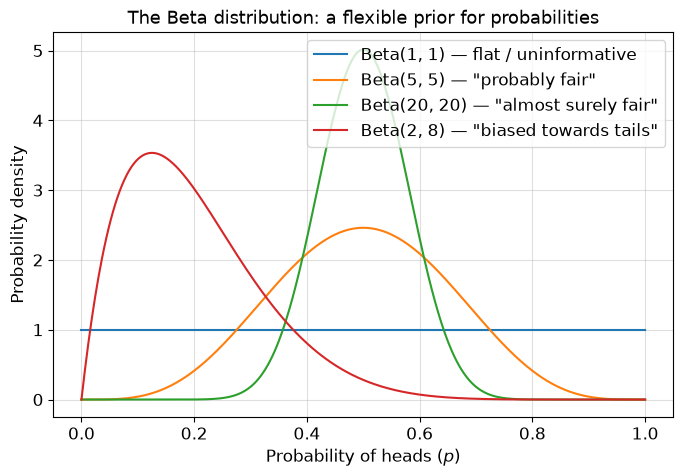

In [3]:
p = np.linspace(0, 1, 500)

plt.figure(figsize=(8, 5))
for a, b, label in [(1, 1, 'Beta(1, 1) — flat / uninformative'),
                    (5, 5, 'Beta(5, 5) — "probably fair"'),
                    (20, 20, 'Beta(20, 20) — "almost surely fair"'),
                    (2, 8, 'Beta(2, 8) — "biased towards tails"')]:
    plt.plot(p, stats.beta.pdf(p, a, b), label=label)

plt.xlabel('Probability of heads ($p$)')
plt.ylabel('Probability density')
plt.title('The Beta distribution: a flexible prior for probabilities')
plt.legend()
plt.grid(True, alpha=0.4)
plt.show()

## 1d. Conjugate priors: the posterior for free

Here is the useful part. If the prior is a Beta distribution and the likelihood is binomial, the posterior is **also a Beta distribution**, with parameters you can write down instantly:

$$
\mathrm{Beta}(\alpha, \beta) \;+\; \underbrace{k \text{ heads in } n \text{ flips}}_{\text{data}} \;\;\longrightarrow\;\; \mathrm{Beta}(\alpha + k,\; \beta + n - k)
$$

Updating just means adding the observed heads and tails to the prior's pseudo-counts (the Beta prior and the binomial likelihood are built from the same powers of $p$ and $1-p$, so their product stays in the Beta family). No integration, no simulation — the dreaded evidence term cancels out automatically. When the prior and the posterior belong to the same family, the prior is called **conjugate** to the likelihood. A few classic conjugate pairs:

| Likelihood | Conjugate prior | Posterior |
|---|---|---|
| Binomial (counts of successes) | Beta | Beta |
| Normal with known variance (continuous data) | Normal | Normal |
| Poisson (event rates) | Gamma | Gamma |

**If your problem fits a conjugate pair, the entire Bayesian analysis is one line of algebra.** Always check this before reaching for heavier machinery. Let's apply it to our coin.

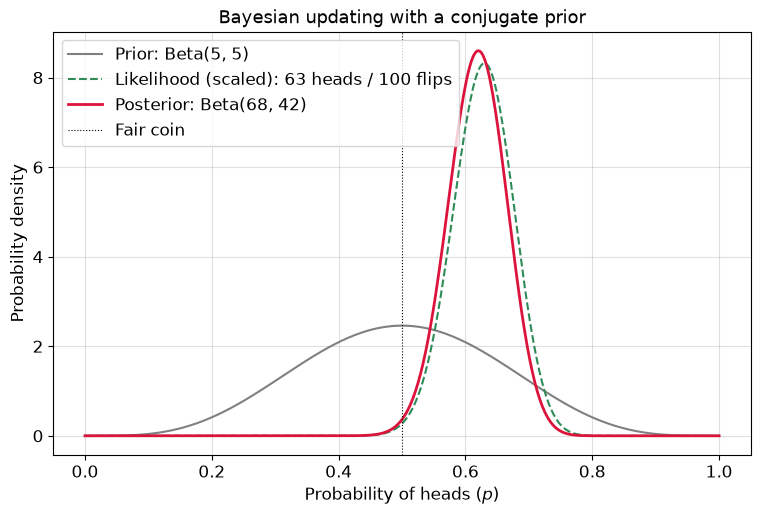

Posterior mean of p:      0.6182
95% credible interval:    [0.5260, 0.7063]


In [4]:
# Data
n = 100   # number of coin flips
k = 63    # number of heads

# Prior: Beta(5, 5) — "probably fair, but not certain"
alpha_prior, beta_prior = 5, 5

# Posterior: conjugacy gives it analytically, in one line
alpha_post = alpha_prior + k          # add the heads
beta_post  = beta_prior + (n - k)     # add the tails

# Prior, (scaled) likelihood and posterior, for plotting
prior_pdf      = stats.beta.pdf(p, alpha_prior, beta_prior)
likelihood     = stats.binom.pmf(k, n, p)
posterior_pdf  = stats.beta.pdf(p, alpha_post, beta_post)

plt.figure(figsize=(9, 5.5))
plt.plot(p, prior_pdf, color='gray', label=f'Prior: Beta({alpha_prior}, {beta_prior})')
plt.plot(p, likelihood / (likelihood.sum() * (p[1] - p[0])), color='seagreen', linestyle='--',
         label=f'Likelihood (scaled): {k} heads / {n} flips')
plt.plot(p, posterior_pdf, color='crimson', linewidth=2,
         label=f'Posterior: Beta({alpha_post}, {beta_post})')
plt.axvline(0.5, color='k', linewidth=0.8, linestyle=':', label='Fair coin')
plt.xlabel('Probability of heads ($p$)')
plt.ylabel('Probability density')
plt.title('Bayesian updating with a conjugate prior')
plt.legend()
plt.grid(True, alpha=0.4)
plt.show()

# Because the posterior is a known distribution, summaries are exact:
post_mean = alpha_post / (alpha_post + beta_post)
ci_low, ci_high = stats.beta.ppf([0.025, 0.975], alpha_post, beta_post)
print(f"Posterior mean of p:      {post_mean:.4f}")
print(f"95% credible interval:    [{ci_low:.4f}, {ci_high:.4f}]")

**What to look for:** the posterior sits between the prior (grey) and the likelihood (green): the data pull it towards 0.63, the prior pulls it towards 0.5. The **95% credible interval** has exactly the interpretation everyone *wants* intervals to have: *given the data, there is a 95% probability that $p$ lies in this range.* (A frequentist confidence interval does not mean that, however much we would like it to.)

---
### ✏️ Your turn

1. Multiply the data by ten (`n = 1000`, `k = 630`) and re-run the cell. What happens to the posterior mean and to the width of the credible interval, and why?
2. Set the data back (`n = 100`, `k = 63`) and make the prior much stronger: `alpha_prior, beta_prior = 200, 200`. Who wins now, the prior or the data? When would such a strong prior be justified?

<details><summary>Show the answers</summary>

1. The mean moves close to 0.630 and the interval shrinks to roughly [0.60, 0.66]: with ten times the data, the likelihood dominates and the prior hardly matters.
2. The posterior mean drops to about 0.53: 398 pseudo-observations outweigh 100 real ones. A prior this strong is justified only if it really does summarise earlier evidence (for example a previous experiment with 400 flips).
</details>

---

---
# Part 2 – A real problem: glacier melt vs air temperature

In climate science, priors let us build **physically grounded** statistical models: we can give the model parameters priors that reflect known physical limits. A frequentist model has no such lever — it listens only to the data, and when the data are scarce or noisy it can produce physically impossible results.

Let's test that claim on real field data.

## 2a. Import and plot the data

`Glac_Melt.csv` was recorded daily on a glacier in Spitsbergen during the summer of 1999 (data courtesy of Prof. Gareth Rees):

| Column | Description | Units |
|--------|-------------|-------|
| `Day` | day number, counting from 1 January | — |
| `AvTemp` | average air temperature for the day | °C |
| `Melt` | measured surface melt | mm |

Glaciological theory says melt is driven by solar radiation, by sensible heat from warm air and by condensation at the ice surface, so we expect a strong, slightly nonlinear relationship between melt and air temperature.

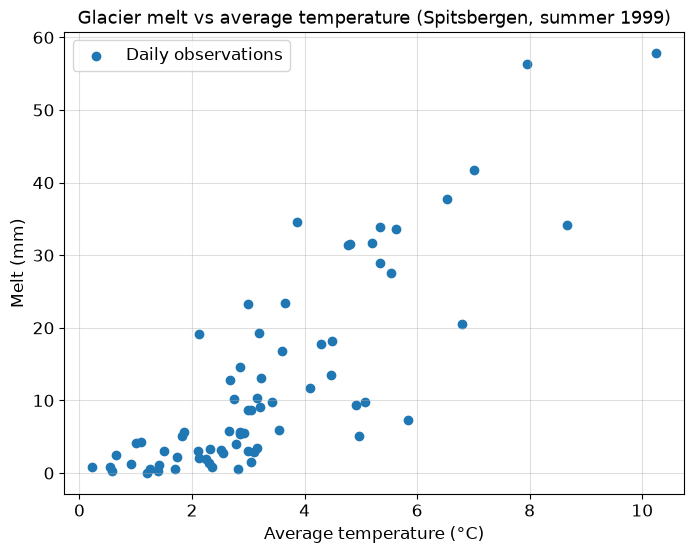

In [5]:
data = pd.read_csv(MELT_FILE)

av_temp = data['AvTemp']
melt = data['Melt']

plt.figure(figsize=(8, 6))
plt.scatter(av_temp, melt, marker='o', label='Daily observations')
plt.title('Glacier melt vs average temperature (Spitsbergen, summer 1999)')
plt.xlabel('Average temperature (°C)')
plt.ylabel('Melt (mm)')
plt.legend()
plt.grid(True, alpha=0.4)
plt.show()

## 2b. The frequentist fit

The relationship bends slightly upwards — glaciers typically have a threshold temperature above which melt accelerates (for example through the albedo feedback). A quadratic model captures this:

$$
\mathrm{Melt} = \beta_0 + \beta_1 \cdot \mathrm{AvTemp} + \beta_2 \cdot \mathrm{AvTemp}^2 + \epsilon, \qquad \epsilon \sim \mathcal{N}(0, \sigma^2)
$$

where $\beta_0$ is the intercept, $\beta_1$ and $\beta_2$ the linear and quadratic coefficients, and $\epsilon$ the noise. The cell fits it the classical way with `np.polyfit`, which returns the best-fit coefficients but no uncertainties.

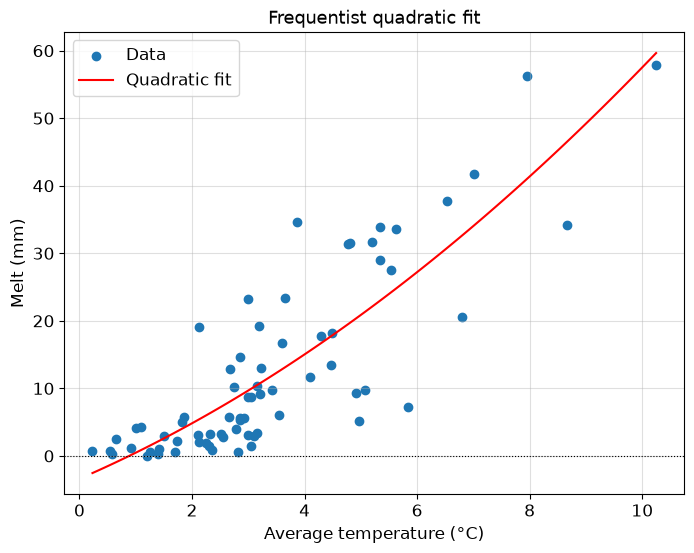

β₂ (quadratic term): 0.2478
β₁ (linear term):    3.6130
β₀ (intercept):      -3.3847   <-- look closely at this one
R²:                  0.7076


In [6]:
b2, b1, b0 = np.polyfit(av_temp, melt, 2)   # highest degree first

# Smooth curve for plotting
curve_x = np.linspace(av_temp.min(), av_temp.max(), 100)
curve_y = np.polyval([b2, b1, b0], curve_x)

plt.figure(figsize=(8, 6))
plt.scatter(av_temp, melt, marker='o', label='Data')
plt.plot(curve_x, curve_y, color='red', label='Quadratic fit')
plt.axhline(0, color='k', linewidth=0.8, linestyle=':')
plt.title('Frequentist quadratic fit')
plt.xlabel('Average temperature (°C)')
plt.ylabel('Melt (mm)')
plt.legend()
plt.grid(True, alpha=0.4)
plt.show()

# Goodness of fit: R^2
predicted = np.polyval([b2, b1, b0], av_temp)
residuals = melt - predicted
r_squared = 1 - np.sum(residuals**2) / np.sum((melt - melt.mean())**2)

print(f"β₂ (quadratic term): {b2:.4f}")
print(f"β₁ (linear term):    {b1:.4f}")
print(f"β₀ (intercept):      {b0:.4f}   <-- look closely at this one")
print(f"R²:                  {r_squared:.4f}")

## 2c. The red flag

The model explains a large share of the variance ($R^2 \approx 0.7$) and the curve looks reasonable. But:

> **The intercept is negative — the model predicts *negative melting* at 0 °C. That is physically impossible.**

The frequentist model fits the observations well, yet it violates the physics — a direct consequence of a small, noisy dataset. We could hunt for outliers, or spend a field season collecting more measurements. Or we can go Bayesian and put the physics directly into the model, through a prior that says the intercept cannot be negative.

---
# Part 3 – When the shortcut fails: MCMC

## 3a. Why conjugacy does not help here

With the coin, a conjugate prior gave us the posterior in one line. Can we do that here? No:

* our model has **four unknowns** $(\beta_2, \beta_1, \beta_0, \sigma)$, not one;
* and the physical constraint needs a **truncated prior** on the intercept ($\beta_0 \geq 0$).

That combination has no conjugate solution — and this is the norm, not the exception: most real-world Bayesian models are not conjugate. What we *can* always compute is the **numerator** of Bayes' theorem, likelihood × prior, for any candidate parameter set. Only the evidence (the normalising integral) is out of reach.

**MCMC** (Markov chain Monte Carlo) algorithms exploit exactly this: they draw samples whose long-run distribution is the posterior, using only the un-normalised numerator. The sampler wanders through parameter space and spends time in each region in proportion to its posterior probability. The simplest recipe, the **Metropolis algorithm**:

1. **Start** from a guess for the parameters.
2. **Propose** a small random step away from the current parameters.
3. **Accept or reject**: if the proposal has a higher posterior, accept it; if lower, accept it only sometimes — with a probability equal to the ratio of the two posteriors. (This occasional acceptance of worse states is what lets the chain explore the whole posterior instead of getting stuck on one peak.)
4. **Repeat** thousands of times, collecting the visited states into a *chain*.

Here is the algorithm running on exactly the model you are about to build — the left panel walks through parameter space (green = accepted proposal, red = rejected), and the right panel shows the regression curve of the current state:

![MCMC on the glacier model](figures/mcmc_glacier.gif)

*The chain starts from a poor guess, quickly finds the high-probability region, and then keeps exploring it. Note how the cloud of samples piles up against the physical limit $\beta_0 \geq 0$ without ever crossing it. The bottom panel tracks the (log) posterior of the current state: after the initial climb — called the **burn-in** — the chain does not settle at the peak. It keeps wandering around the high-probability region *on purpose*, because the goal is not the single best parameter set but the whole posterior distribution.*

## 3b. The likelihood

We now write the ingredients as Python functions. First the variables, then the likelihood: the probability of the melt observations $y$ given a candidate parameter set. Since the model assumes Gaussian noise, we compute the model prediction, take the residuals, and score them under $\mathcal{N}(0, \sigma)$.

One practical point: we always work with the **logarithm** of these probabilities. A product of 70 small probabilities underflows to zero on a computer, whereas a sum of 70 logs is perfectly stable.

In [7]:
# Independent (x) and dependent (y) variables as NumPy arrays
x = data['AvTemp'].values
y = data['Melt'].values

def log_likelihood(params):
    b2, b1, b0, sigma = params
    pred = b2 * x**2 + b1 * x + b0            # model prediction
    residuals = y - pred                      # misfit to observations
    return -0.5 * np.sum((residuals / sigma)**2 + np.log(2 * np.pi * sigma**2))

## 3c. The priors — where the physics goes in

One prior per parameter:

* $\beta_2, \beta_1 \sim \mathcal{N}(0, 10)$ — weakly informative; we have no strong opinion about the curvature or slope.
* $\beta_0 \sim \mathcal{U}(0, 5)$ — **here is our physical knowledge**: no negative melting in nature. The hard lower bound at 0 encodes the physical law.
* $\sigma \sim \mathcal{U}(0.1, 30)$ — the noise level must be positive; we allow a generous range.

The function below returns the **log prior** of a candidate. If the candidate falls outside the hard bounds it returns $-\infty$ — zero prior probability, so the sampler will *never* accept it. This is how the constraint $\beta_0 \geq 0$ is enforced.

The log posterior (up to the unknown normalising constant, which is all MCMC needs) is then simply **log-likelihood + log-prior**.

In [8]:
def log_prior(params):
    b2, b1, b0, sigma = params
    # Hard physical bounds: zero probability outside them
    if not (0 <= b0 <= 5) or not (0.1 <= sigma <= 30):
        return -np.inf
    # Weakly informative normal priors on the polynomial coefficients
    log_p_b2 = -0.5 * (b2 / 10)**2
    log_p_b1 = -0.5 * (b1 / 10)**2
    return log_p_b2 + log_p_b1     # (constant terms omitted — they cancel in the ratio)

def log_posterior(params):
    lp = log_prior(params)
    if not np.isfinite(lp):
        return -np.inf             # don't waste time computing the likelihood
    return lp + log_likelihood(params)

## 3d. The proposal and the sampler

The **proposal** suggests a new candidate by adding a little Gaussian noise to the current parameters. The `step_sizes` control how far each proposal can jump, and they are the key tuning knob of the algorithm: steps too large and almost everything is rejected; steps too small and the chain crawls. A rule of thumb is to aim for an acceptance rate of roughly 20–40%. (The values below are tuned for you — the *Your turn* box in Part 4 lets you break them.)

The **sampler** then repeats propose–accept–reject many times. Because we work with logs, "accept with probability equal to the ratio of posteriors" becomes a simple subtraction. One housekeeping detail: the first few thousand samples are biased by the arbitrary starting point (the burn-in climb in the animation), so we throw them away.

In [9]:
step_sizes = np.array([0.08, 0.3, 0.5, 0.4])   # tuned for (b2, b1, b0, sigma)

def proposal(current_params):
    return current_params + rng.normal(0, step_sizes)

# Note: if a proposal lands outside the prior bounds, log_prior returns -inf
# and the sampler below automatically rejects it. The physics polices itself.

def run_mcmc(initial_params, iterations=100_000, burnin=5_000):
    samples = []
    current = np.array(initial_params, dtype=float)
    current_logpost = log_posterior(current)
    n_accepted = 0

    for i in range(iterations):
        proposed = proposal(current)
        proposed_logpost = log_posterior(proposed)

        # Metropolis acceptance test (in log space)
        if np.log(rng.random()) < proposed_logpost - current_logpost:
            current, current_logpost = proposed, proposed_logpost
            n_accepted += 1

        if i >= burnin:
            samples.append(current)

    print(f"Acceptance rate: {n_accepted / iterations:.1%}")
    return np.array(samples)

## 3e. Run it

We start the chain from a deliberately mediocre guess (as in the animation) and let it run for 100,000 iterations — for a 4-parameter model this takes a few seconds. For bigger models you would run several chains for much longer and check convergence with formal diagnostics; today a visual check will do.

In [10]:
samples = run_mcmc(initial_params=[0.0, 1.0, 2.5, 5.0])
print(f"Number of posterior samples kept: {len(samples)}")

Acceptance rate: 32.2%
Number of posterior samples kept: 95000


---
# Part 4 – Did it work? Diagnostics and results

## 4a. Trace plots

Before trusting any result, we look at the **trace plots** — the value of each parameter along the chain. A healthy, well-mixed chain looks like a "hairy caterpillar": rapid fluctuation around a stable level, with no drifts and no long flat stretches.

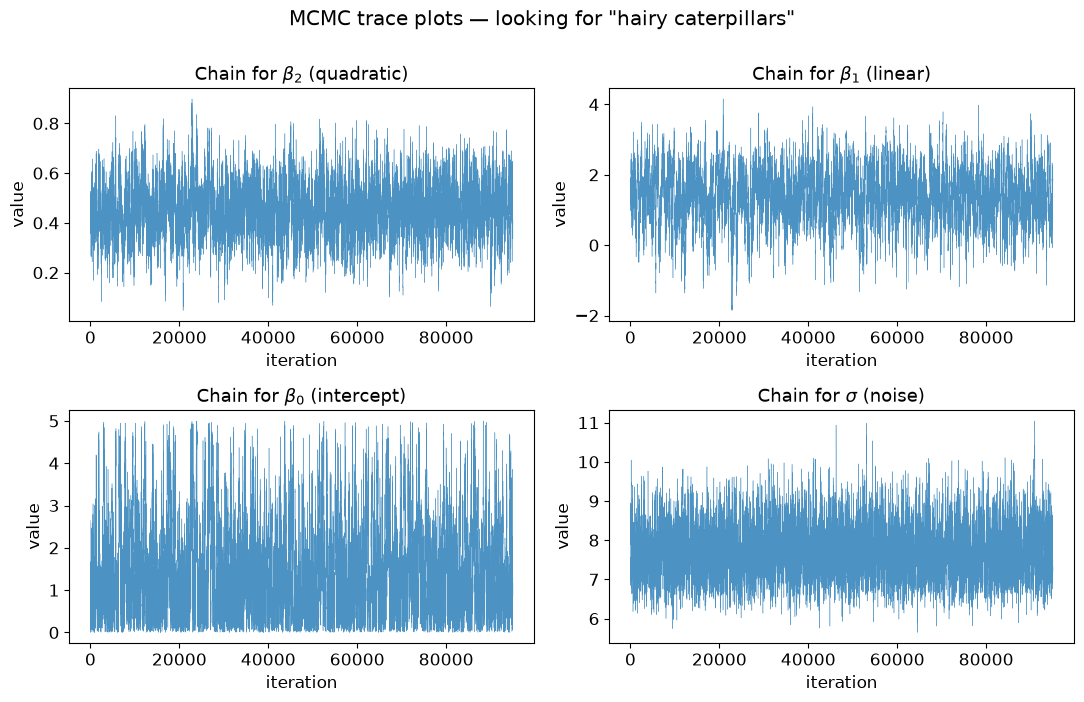

In [11]:
fig, axes = plt.subplots(2, 2, figsize=(11, 7))
labels = [r'$\beta_2$ (quadratic)', r'$\beta_1$ (linear)', r'$\beta_0$ (intercept)', r'$\sigma$ (noise)']

for i, ax in enumerate(axes.flatten()):
    ax.plot(samples[:, i], linewidth=0.3, alpha=0.8)
    ax.set_title(f'Chain for {labels[i]}')
    ax.set_xlabel('iteration')
    ax.set_ylabel('value')

fig.suptitle('MCMC trace plots — looking for "hairy caterpillars"', y=1.0)
plt.tight_layout()
plt.show()

## 4b. The posteriors

Now the payoff: the posterior distribution of every parameter. We overlay the frequentist point estimates (red dashed lines) for comparison.

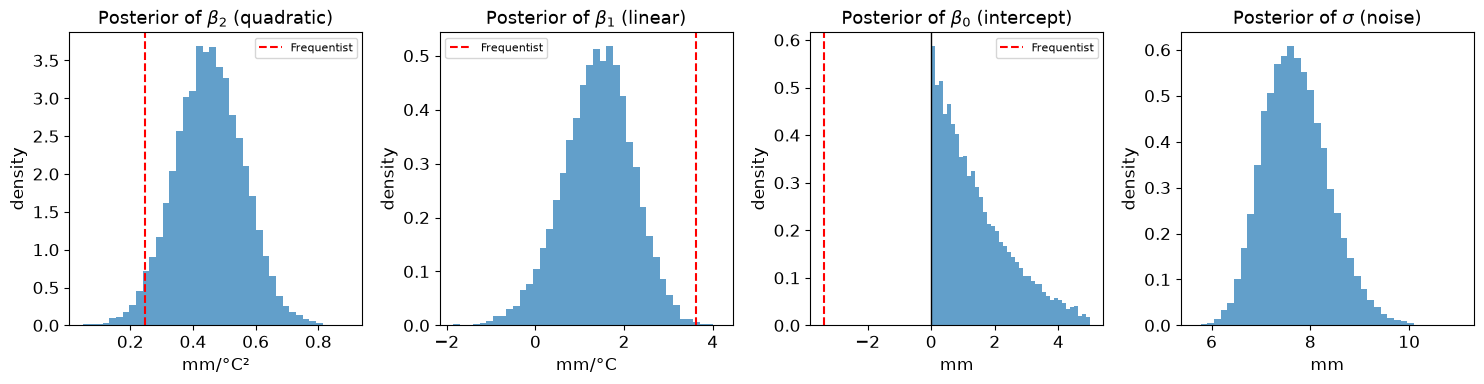

parameter     post. mean       95% credible interval
beta_2             0.452              [0.239, 0.664]
beta_1             1.407             [-0.242, 2.885]
beta_0             1.398              [0.042, 4.196]
sigma              7.718              [6.567, 9.122]


In [12]:
frequentist = [b2, b1, b0]   # from Part 2
units = ['mm/°C²', 'mm/°C', 'mm', 'mm']

fig, axes = plt.subplots(1, 4, figsize=(15, 4))
for i, ax in enumerate(axes):
    ax.hist(samples[:, i], bins=40, density=True, alpha=0.7)
    ax.set_title(f'Posterior of {labels[i]}')
    ax.set_xlabel(units[i])
    ax.set_ylabel('density')
    if i < 3:
        ax.axvline(frequentist[i], color='red', linestyle='--', label='Frequentist')
        ax.legend(fontsize=8)
    if i == 2:
        ax.axvline(0, color='k', linewidth=1)

plt.tight_layout()
plt.show()

# Posterior summaries
print(f"{'parameter':<12}{'post. mean':>12}{'95% credible interval':>28}")
for i, name in enumerate(['beta_2', 'beta_1', 'beta_0', 'sigma']):
    lo, hi = np.percentile(samples[:, i], [2.5, 97.5])
    print(f"{name:<12}{samples[:, i].mean():>12.3f}{f'[{lo:.3f}, {hi:.3f}]':>28}")

**What to look for:** the intercept $\beta_0$. The frequentist estimate sits at a *physically impossible* negative value, while the Bayesian posterior respects the limit — its entire mass lies above zero, piling up near the boundary exactly as in the animation. Instead of a single impossible number we now have a full distribution of plausible, physical values.

Two honest footnotes. First, the *upper* end of the $\beta_0$ interval is partly set by our prior too: we said $\beta_0 \leq 5$, and the posterior still has density near 5, so that arbitrary bound is doing some work — change it and the interval changes (this is why the conclusions insist on prior-sensitivity checks). Second, compare $\beta_1$ and $\beta_2$ with their frequentist values: forcing the intercept up pushes the linear term down and the curvature up. The parameters trade off against each other — a constraint on one moves the others.

---
### ✏️ Your turn

Re-run the sampler (the cell in 3e) with much smaller steps and with much larger ones, and look at the acceptance rate and the trace plots each time:

```python
step_sizes = np.array([0.08, 0.3, 0.5, 0.4]) * 0.1   # then * 10
```

When do the chains look "hairy" (good mixing), and when do they look "sticky" (poor mixing)? Set `step_sizes` back to the original values and re-run before moving on.

<details><summary>Show the answers</summary>

* × 0.1: the acceptance rate jumps to ~90%, but each step is tiny — the traces wander slowly up and down (long waves instead of fuzz). The chain explores the posterior very inefficiently.
* × 10: the acceptance rate collapses to a few percent — the traces show long flat stretches where every proposal was rejected.
* The tuned values give ~20–40% acceptance and fuzzy, stable traces: that is the sweet spot.
</details>

---

**A cautionary note.** Metropolis is the simplest MCMC sampler, and it works well for low-dimensional models like ours. For bigger problems you would use a library with smarter samplers — for example [PyMC](https://www.pymc.io/) or [emcee](https://emcee.readthedocs.io/) — but the concepts you just learned (priors, posteriors, acceptance, burn-in, trace plots) transfer directly.

## 4c. The Bayesian model fit

Finally, the fit itself. Every posterior sample defines a candidate curve, and the spread of those curves *is* our uncertainty. We summarise it with the posterior-mean curve and a **95% credibility band** — the Bayesian counterpart of a confidence band, with the more natural interpretation.

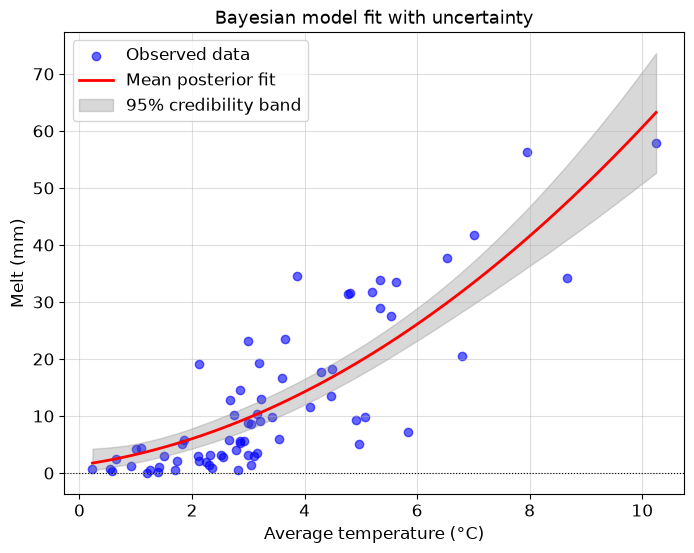

In [13]:
# One predicted curve per posterior sample
x_range = np.linspace(x.min(), x.max(), 100)
predictions = (samples[:, 0:1] * x_range**2      # b2 * x^2
               + samples[:, 1:2] * x_range       # b1 * x
               + samples[:, 2:3])                # b0

mean_prediction = predictions.mean(axis=0)
lower, upper = np.percentile(predictions, [2.5, 97.5], axis=0)

plt.figure(figsize=(8, 6))
plt.scatter(x, y, color='blue', alpha=0.6, label='Observed data')
plt.plot(x_range, mean_prediction, color='red', linewidth=2, label='Mean posterior fit')
plt.fill_between(x_range, lower, upper, color='gray', alpha=0.3, label='95% credibility band')
plt.axhline(0, color='k', linewidth=0.8, linestyle=':')
plt.xlabel('Average temperature (°C)')
plt.ylabel('Melt (mm)')
plt.title('Bayesian model fit with uncertainty')
plt.legend()
plt.grid(True, alpha=0.4)
plt.show()

Unlike the frequentist fit, the Bayesian model never predicts negative melting — even at the lower edge of the credibility band. The physics we wrote into the prior propagates all the way through to the predictions. (This is still a simple model: a quadratic may not be the ideal shape for melt, and a serious analysis would compare alternative models.)

## 4d. Beyond model error: measurement error

One loose end. The $\sigma$ in our model captures the **model error** — scatter that our quadratic does not explain. But the melt *measurements themselves* also carry error: no instrument is perfect. Suppose the melt sensor has an error of about 5% of the reading, $\tau_i = 0.05 \cdot \hat{y}_i$. Because model error and measurement error are independent, their **variances simply add**:

$$
\mathrm{Var}(y_{obs}) = \sigma^2 + \tau^2
$$

Folding this into the model takes one change to the likelihood — replace $\sigma^2$ with the total variance. **Read the next cell, no need to run it today** — but keep the idea in mind, because two of the group tasks use datasets that come *with* an uncertainty column, and this is exactly how it enters the model.

In [14]:
# Concept only — read this, no need to run it today.
# The ONLY change from log_likelihood() in Section 3b is the total_variance line.

def log_likelihood_with_measurement_error(params):
    b2, b1, b0, sigma = params
    pred = b2 * x**2 + b1 * x + b0

    measurement_error = 0.05 * np.abs(pred)             # tau: assumed 5% sensor error
    total_variance = sigma**2 + measurement_error**2    # variances add

    residuals = y - pred
    return -0.5 * np.sum(residuals**2 / total_variance + np.log(2 * np.pi * total_variance))

---
## Conclusions and caveats

**Conclusions**

* **Bayesian analysis** updates a prior belief with data into a posterior distribution. It shines for small, noisy datasets — the Earth-science norm — and lets us encode physical limits directly into statistical models.
* **Conjugate priors** are the special cases where the posterior has a closed form (Beta–binomial, Normal–Normal, Gamma–Poisson). When your problem fits one, the full answer costs one line of algebra — always check first.
* **MCMC** handles everything else. The Metropolis sampler explores parameter space using only likelihood × prior; tuning the step sizes, discarding the burn-in and checking the trace plots are part of the craft.
* On the glacier data, the frequentist fit predicted negative melt; a prior with a hard bound at zero fixed it, and the whole posterior — and every prediction drawn from it — respects the physics.

**Caveats**

* The result depends on the prior: every prior choice must be stated and justified, and a sensitivity check (does the answer survive a different reasonable prior?) is good practice.
* A "hairy" trace plot is a necessary check, not a proof of convergence; serious work runs several chains and formal diagnostics.
* The quadratic shape and the Gaussian noise are themselves assumptions, not facts.
* The glacier dataset ships with no measurement uncertainties; the 5% sensor error in 4d was assumed.

## Next steps

The group tasks are in **`Group_tasks.ipynb`** (same folder); they use `bayes_helpers.py`, which packages the same sampler and models in fewer lines. Each group applies today's machinery to a real climate question: the rate of global warming, the timing of the end of the last ice age, or a forecast of Arctic sea ice.

### Before class – checklist

* [ ] Run `python check_setup.py`, then this whole notebook once (restart the kernel and run all cells).
* [ ] Answer the two *Your turn* boxes.
* [ ] Write down one sentence: what does a *credible interval* mean?

---
## Cheat sheet: the main calls we used

| Call | What it does |
|---|---|
| `stats.beta.pdf(p, a, b)` | density of a Beta distribution (our prior and posterior for the coin) |
| `stats.binom.pmf(k, n, p)` | probability of k successes in n tries (the coin likelihood) |
| `stats.beta.ppf([0.025, 0.975], a, b)` | exact 95% credible interval of a Beta posterior |
| `np.polyfit(x, y, 2)` / `np.polyval(...)` | classical quadratic fit and its predictions |
| `rng.normal(0, step_sizes)` | the Gaussian proposal step of the sampler |
| `np.percentile(samples, [2.5, 97.5], axis=0)` | credible intervals from MCMC samples |

## Glossary

* **Prior** – what we believe about a parameter before seeing the data, written as a probability distribution.
* **Likelihood** – how probable the observed data would be for a given candidate value of the parameters.
* **Posterior** – the updated belief after seeing the data: posterior ∝ likelihood × prior.
* **Evidence** – the normalising constant of Bayes' theorem; hard to compute, and the reason MCMC exists.
* **Conjugate prior** – a prior that keeps the posterior in the same family, so the update is a formula, not a computation.
* **Credible interval** – an interval holding, say, 95% of the posterior: given the data, the parameter is 95% likely to be inside.
* **MCMC** – Markov chain Monte Carlo: algorithms that draw samples from the posterior using only likelihood × prior.
* **Metropolis algorithm** – the simplest MCMC recipe: propose a random step, accept or reject by the posterior ratio.
* **Acceptance rate** – the share of proposals accepted; roughly 20–40% is healthy for Metropolis.
* **Burn-in** – the first part of the chain, still influenced by the starting point; discarded.
* **Trace plot** – a parameter's value along the chain; "hairy caterpillar" = good mixing.
* **Credibility band** – the credible interval of the model *curve*, computed from all posterior sample curves.
* **Model error vs measurement error** – scatter the model cannot explain (σ) vs the instrument's own uncertainty (τ); their variances add.

## References

* Kruschke, J.K., 2010. Bayesian data analysis. *WIREs Cognitive Science*, 1(5), 658–676. https://doi.org/10.1002/wcs.72
* Chib, S. and Greenberg, E., 1995. Understanding the Metropolis–Hastings algorithm. *The American Statistician*, 49(4), 327–335. https://doi.org/10.1080/00031305.1995.10476177
* Martin, O.A., Kumar, R. and Lao, J., 2021. *Bayesian Modeling and Computation in Python.* Chapman and Hall/CRC. Free online edition: https://bayesiancomputationbook.com
* Glacier data: courtesy of Prof. Gareth Rees (Scott Polar Research Institute, University of Cambridge).

---

*Instructor: Francesco Muschitiello (fm476), October 2026.*
